### Imports

In [2]:
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
import sys
from pathlib import Path

ROOT = next(
    (parent for parent in (Path.cwd(), *Path.cwd().parents)
     if (parent / "src" / "paths.py").is_file()),
    None,
)
if ROOT is None:
    raise FileNotFoundError("Could not locate project root containing src/paths.py")
sys.path.insert(0, str(ROOT))


from src.paths import *
from src.data_validation import validate_grid
from src.graph_utils import build_grid_graph

### Load the datasets

In [3]:
substations_path = GIS / "grid_substations.csv"
lines_path = GIS / "transmission_lines.csv"
if substations_path.is_file() and lines_path.is_file():
    substations = pd.read_csv(substations_path)
    transmission_lines = pd.read_csv(lines_path)
    validate_grid(substations, transmission_lines)
else:
    print("Grid graph construction skipped: completed GIS inputs are missing.")
    print(f"Provide {substations_path.name} and {lines_path.name} in {GIS}.")
    print("Start from datasets/templates/grid_substations_template.csv and transmission_lines_template.csv.")
    substations = pd.DataFrame(columns=["bus_id", "name", "latitude", "longitude", "voltage_kv"])
    transmission_lines = pd.DataFrame(columns=["from_bus", "to_bus", "length_km"])

Grid graph construction skipped: completed GIS inputs are missing.
Provide grid_substations.csv and transmission_lines.csv in D:\My_Project\Analyse\4G-Network-Coverage-Optimization\datasets\raw\gis.
Start from datasets/templates/grid_substations_template.csv and transmission_lines_template.csv.


### Construct the graph

In [4]:
G = build_grid_graph(
    substations,
    transmission_lines
)

print("Number of nodes:", G.number_of_nodes())
print("Number of edges:", G.number_of_edges())

print("Is connected:", nx.is_connected(G) if G.number_of_nodes() else False)
print("Connected components:", nx.number_connected_components(G))

Number of nodes: 0
Number of edges: 0
Is connected: False
Connected components: 0


### Examine graph properties

In [5]:
print("Graph density:", nx.density(G))

if G.number_of_nodes():
    print("Average degree:", sum(dict(G.degree()).values()) / G.number_of_nodes())
    print("Largest connected component:", len(max(nx.connected_components(G), key=len)))
else:
    print("Network metrics unavailable: no substations were loaded.")

Graph density: 0
Network metrics unavailable: no substations were loaded.


### Visualize the transmission graph

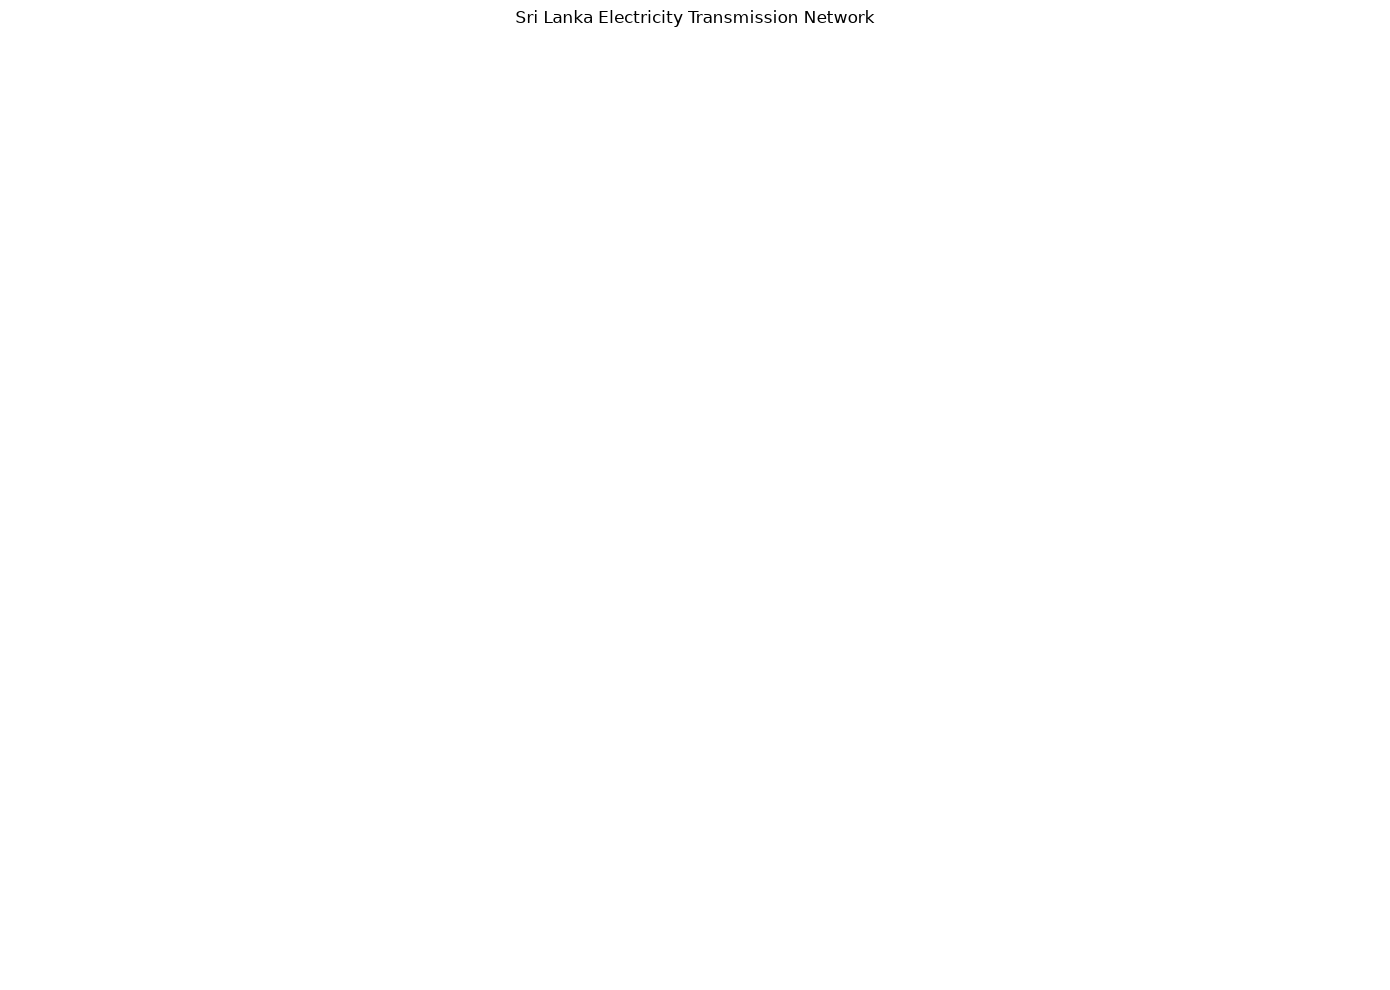

In [6]:
plt.figure(figsize=(14, 10))

pos = nx.spring_layout(
    G,
    seed=42,
    weight="length_km"
)

nx.draw_networkx_nodes(
    G, pos,
    node_size=100
)

nx.draw_networkx_edges(
    G, pos,
    width=0.8,
    alpha=0.5
)

nx.draw_networkx_labels(
    G, pos,
    font_size=6
)

plt.title("Sri Lanka Electricity Transmission Network")
plt.axis("off")
plt.tight_layout()

plt.savefig(
    GRAPHS / "transmission_network.png",
    dpi=300
)

plt.show()

### Export graph information

In [7]:
if G.number_of_nodes() > 0:
    nodes = pd.DataFrame([
        {
            "bus_id": node,
            **attributes
        }
        for node, attributes in G.nodes(data=True)
    ])
else:
    nodes = pd.DataFrame(columns=["bus_id", "name", "latitude", "longitude", "voltage_kv"])

if G.number_of_edges() > 0:
    edges = pd.DataFrame([
        {
            "from_bus": u,
            "to_bus": v,
            **attributes
        }
        for u, v, attributes in G.edges(data=True)
    ])
else:
    edges = pd.DataFrame(columns=["from_bus", "to_bus", "length_km"])

nodes.to_csv(
    PROCESSED / "grid_nodes.csv",
    index=False
)

edges.to_csv(
    PROCESSED / "grid_edges.csv",
    index=False
)
